# 6주차 이론 예제 — 워크북 코드를 한 셀씩 실행해 보기

**인공지능과 데이터 활용 · 고객 리뷰 데이터의 가공 및 분석**

이론 시간에 **노션 본문 순서대로, 한 셀씩 실행하며** 설명하는 노트북입니다. 예제마다 작은 셀(**▶ 셀 N-1, N-2 …**)로 나뉘어 있고,
셀마다 **실행 후 확인**할 내용이 적혀 있습니다. 노션 3장의 🐍 예제 토글과 셀 번호·코드가 같습니다. 외부 데이터 없이 실행됩니다(약 20초).

| 노션 이론 | 예제 (셀 수) |
|---|---|
| 3.0 공통 파이썬 기초 | 예제 1. 도구 상자 가져오기 — import와 주석 (1)<br>예제 2. 후기 한 줄 다루기 — 문자열 (2)<br>예제 3. 여러 후기 다루기 — 리스트와 반복문 (3)<br>예제 4. 별점을 라벨로 바꾸기 — 딕셔너리와 f-문자열 (2)<br>예제 5. 판단을 함수로 묶기 — def와 조건 표현식 (2)<br>예제 6. 후기 표 만들기 — DataFrame·열·.str·새 열 (3)<br>예제 7. 조건으로 후기 고르기 — 불리언 필터 (3)<br>예제 8. 열 전체 값 바꾸기 — map·lambda·np.where (3)<br>예제 9. 묶어서 세고 평균 내기 — value_counts·groupby·crosstab (3) |
| 3.1 텍스트 데이터와 감성분석 | 예제 10. 별점으로 라벨 붙이기와 라벨 잡음 (2) |
| 3.2 감성데이터 수집 (워크북 0) | 예제 11. 탭으로 구분된 원자료 읽기 — read_csv 옵션 (2)<br>예제 12. 복사·도배 후기 걸러내기 — 중복 제거 (2)<br>예제 13. 개인정보 의심 문장 걸러내기 — 정규표현식 search (2)<br>예제 14. 별점마다 같은 수 뽑기 — 층화 추출과 난수 시드 (3)<br>예제 15. 해시 동작 원리 — MD5 파일 지문 (2) |
| 3.3 텍스트 전처리와 탐색 (워크북 1) | 예제 16. 공백·반복 글자 정리하기 — re.sub (2)<br>예제 17. 어절 꺼내 빈도 세기 — re.findall·Counter (2) |
| 3.4 수작업 키워드 규칙 분류 (워크북 2) | 예제 18. 단어가 몇 개 들어 있나 세기 — in과 sum (2)<br>예제 19. 키워드 규칙 v1과 실패 사례 (2)<br>예제 20. 부정 표현 가중치로 규칙 v2 만들기 (1) |
| 3.5 AI 감성분석 — TF-IDF + 로지스틱 회귀 (워크북 3) | 예제 21. 문장을 글자 조각으로 자르기 — char n-gram (1)<br>예제 22. TF-IDF 값 읽기와 fit·transform 구분 (3)<br>예제 23. 로지스틱 회귀로 감성 학습·예측하기 (3)<br>예제 24. 확률 계산 원리 — 시그모이드 직접 계산 (2) |
| 3.6 비교·평가 (워크북 4) | 예제 25. 혼동행렬과 정확도·정밀도·재현율 직접 세기 (2)<br>예제 26. 일치율의 함정 — 둘 다 틀려도 일치 (2) |

**사용법:** 맨 위 **준비** 셀과 **셀 1-1**을 먼저 실행한 뒤, 위에서부터 `Shift+Enter`로 한 셀씩 실행합니다.
뒤의 예제는 앞에서 만든 변수(`df`, `to_label`, `rule`, `vec2`, `model` 등)를 이어서 씁니다. 중간에 런타임이 끊기면 `런타임 → 이전 셀 실행`.

## 준비

In [1]:
!pip -q --disable-pip-version-check install koreanize-matplotlib      # 그래프 한글 표시 (처음 한 번)

---
## 3.0 공통 파이썬 기초 — 워크북 전체에서 쓰는 코드
워크북 0~4 어디에서나 나오는 기본 문법입니다. 이론 3장을 시작하기 전에 한 번에 정리합니다.

### 예제 1. 도구 상자 가져오기 — import와 주석
분석에 필요한 도구(모듈)를 가져옵니다. 노트북을 열면 이 셀부터 실행합니다.

**▶ 셀 1-1. 도구 가져오기** — 실행 후 확인: 버전 번호가 출력되면 준비 완료. `ModuleNotFoundError`가 나면 맨 위 `!pip` 셀을 먼저 실행

In [2]:
import io, re, hashlib                  # 파이썬 기본 모듈: 문자열을 파일처럼, 정규표현식, 해시
from collections import Counter         # 개수 세기 도구 하나만 꺼내 오기
import numpy as np                      # 숫자 계산 (np 라는 줄임 이름)
import pandas as pd                     # 표(DataFrame) 다루기 (pd 라는 줄임 이름)
import matplotlib.pyplot as plt         # 그래프
import warnings; warnings.filterwarnings("ignore")   # 버전 차이 경고 숨김
import koreanize_matplotlib             # 그래프 한글 표시
plt.rcParams["axes.unicode_minus"] = False   # 음수 기호 깨짐 방지
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.0.2


| 문법 | 뜻 |
|---|---|
| `import 모듈` | 도구 상자(모듈)를 가져옴 |
| `import pandas as pd` | 가져오면서 줄여 부를 이름 `pd`를 붙임 |
| `from collections import Counter` | 상자 안의 도구 하나만 꺼내 옴 |
| `# 설명` | 주석: `#` 뒤는 실행되지 않는 설명 |

**워크북에서 쓰는 곳:** 모든 워크북의 첫 셀

### 예제 2. 후기 한 줄 다루기 — 문자열
후기 한 줄은 **문자열(str)** 입니다. 앞뒤 공백을 지우고, 글자 수를 세고, 어떤 말이 들어 있는지 확인합니다.

**▶ 셀 2-1. 앞뒤 공백 지우고 글자 수 세기** — 실행 후 확인: 따옴표 안 앞뒤 공백이 사라지고 글자 수가 11인지

In [3]:
review = "  배송이 너어어무 느림  "        # 실제 수업 후기 R059 (앞뒤 공백을 일부러 붙임)
print(repr(review))                         # repr: 공백까지 보이게 출력
clean = review.strip()                      # 앞뒤 공백 제거 → 새 문자열 (review 는 그대로)
print(repr(clean), "| 글자 수:", len(clean))

'  배송이 너어어무 느림  '
'배송이 너어어무 느림' | 글자 수: 11


**▶ 셀 2-2. 들어 있는 말 확인하고 바꾸기** — 실행 후 확인: `True False`, `별로`

In [4]:
print("느림" in clean, "좋아" in clean)      # in: 부분 문자열이 들어 있으면 True
print("별루".replace("루", "로"))           # 바꾸기

True False
별로


| 문법 | 뜻 |
|---|---|
| `"..."` | 문자열 (작은따옴표 `'...'`도 같음) |
| `s.strip()` | 앞뒤 공백 제거한 새 문자열 |
| `len(s)` | 글자 수 (공백 포함) |
| `"a" in s` | `a`가 들어 있으면 `True`, 없으면 `False` |
| `s.replace(a, b)` | a를 b로 바꾼 새 문자열 |

**워크북에서 쓰는 곳:** 0-4 길이 필터, 1-3 정리, 2-2 규칙

**직접 바꿔 보기:** `review`를 다른 후기로 바꾸고 `len`과 `in` 결과를 확인

### 예제 3. 여러 후기 다루기 — 리스트와 반복문
여러 후기는 **리스트(list)** 에 담고, `for` 반복문으로 하나씩 꺼내 처리합니다.

**▶ 셀 3-1. 리스트 만들고 꺼내기** — 실행 후 확인: 첫 번째는 `[0]`, 마지막은 `[-1]`

In [5]:
reviews = ["배송이 너어어무 느림", "세팅력이 우수합니다", "접착성 완전 안좋아요ㅜ"]
print("개수:", len(reviews), "| 첫 번째:", reviews[0], "| 마지막:", reviews[-1])

개수: 3 | 첫 번째: 배송이 너어어무 느림 | 마지막: 접착성 완전 안좋아요ㅜ


**▶ 셀 3-2. for 반복문으로 하나씩 처리** — 실행 후 확인: 세 줄이 번호와 함께 출력되는지

In [6]:
for i, r in enumerate(reviews, start=1):    # 번호(i)와 값(r)을 함께 꺼내며 반복
    print(f"{i}번 후기 ({len(r)}자): {r}")   # 반복할 줄은 4칸 들여쓰기

1번 후기 (11자): 배송이 너어어무 느림
2번 후기 (10자): 세팅력이 우수합니다
3번 후기 (12자): 접착성 완전 안좋아요ㅜ


**▶ 셀 3-3. 리스트 컴프리헨션** — 실행 후 확인: `[11, 10, 12]`

In [7]:
lengths = [len(r) for r in reviews]         # [식 for 변수 in 목록]
print("길이 목록:", lengths)

길이 목록: [11, 10, 12]


| 문법 | 뜻 |
|---|---|
| `[a, b, c]` | 리스트 |
| `x[0] / x[-1]` | 첫 번째 / 마지막 (번호는 **0부터**) |
| `for r in 목록:` | 목록에서 하나씩 꺼내 아래 들여쓴 줄을 반복 |
| `enumerate(목록, start=1)` | 번호와 값을 함께 꺼냄 |
| `[식 for r in 목록]` | 모든 원소에 식을 적용한 새 리스트 |

**워크북에서 쓰는 곳:** 1-5 어절 모으기, 2-2 규칙 확인, 4-3 사례 출력

**직접 바꿔 보기:** `reviews`에 후기 하나를 추가하고 셀 3-1부터 다시 실행

### 예제 4. 별점을 라벨로 바꾸기 — 딕셔너리와 f-문자열
"별점 → 라벨"처럼 짝지은 정보는 **딕셔너리(dict)** 에 담습니다. 결과는 **f-문자열**로 보기 좋게 출력합니다.

**▶ 셀 4-1. 딕셔너리로 찾기** — 실행 후 확인: `긍정 부정`, `없음`. `label_of[3]`으로 바꾸면 `KeyError`

In [8]:
label_of = {1: "부정", 2: "부정", 4: "긍정", 5: "긍정"}   # {키: 값}
print(label_of[5], label_of[2])
print(label_of.get(3, "없음"))              # 키가 없으면 오류 대신 기본값

긍정 부정
없음


**▶ 셀 4-2. f-문자열로 출력하기** — 실행 후 확인: `정확도 = 0.887  (88.7%)`

In [9]:
acc = 266 / 300
print(f"정확도 = {acc:.3f}  ({acc:.1%})")   # {} 안에 변수, :.3f 소수 셋째 자리, :.1% 퍼센트

정확도 = 0.887  (88.7%)


| 문법 | 뜻 |
|---|---|
| `{키: 값}` | 딕셔너리 |
| `d[키]` | 값 찾기 (키가 없으면 오류) |
| `d.get(키, 기본값)` | 키가 없으면 기본값 |
| `f"{x}"` | f-문자열: `{}` 안에 변수·식을 넣음 |
| `f"{x:.3f}" / f"{x:.1%}"` | 소수 셋째 자리 / 퍼센트 |

**워크북에서 쓰는 곳:** 1-1 라벨 확인, 모든 결과 출력

**직접 바꿔 보기:** `label_of`에 `3: "중립"`을 넣고 `.get(3, ...)` 결과 확인

### 예제 5. 판단을 함수로 묶기 — def와 조건 표현식
같은 판단을 여러 번 쓰려면 **함수**로 묶습니다. 한 줄 `if`(조건 표현식)로 세 갈래 판단도 할 수 있습니다.

**▶ 셀 5-1. 함수 정의하고 한 번 불러 보기** — 실행 후 확인: `긍정`. 정의만 하면 아무것도 출력되지 않고, 불러야(`to_label(5)`) 결과가 나온다

In [10]:
def to_label(rating):                        # 함수 정의: 입력은 rating
    return "긍정" if rating >= 4 else ("부정" if rating <= 2 else "중립")   # 결과를 돌려줌

print(to_label(5))

긍정


**▶ 셀 5-2. 여러 값에 반복 적용** — 실행 후 확인: 3만 `중립`

In [11]:
for r in [5, 4, 3, 2, 1]:
    print(r, "→", to_label(r))

5 → 긍정
4 → 긍정
3 → 중립
2 → 부정
1 → 부정


| 문법 | 뜻 |
|---|---|
| `def 이름(입력):` | 함수 정의. 몸통은 **4칸 들여쓰기** |
| `return 값` | 함수의 결과를 돌려줌 |
| `A if 조건 else B` | 조건이 참이면 A, 거짓이면 B (한 줄 if) |
| `A if 조건1 else (B if 조건2 else C)` | 겹쳐 쓰면 세 갈래 |

**워크북에서 쓰는 곳:** 1-3 clean_text, 2-2 rule

**직접 바꿔 보기:** `return` 줄의 들여쓰기를 지우고 실행하면 어떤 오류가 나는지 확인(`IndentationError`)

### 예제 6. 후기 표 만들기 — DataFrame·열·.str·새 열
pandas의 **DataFrame**은 엑셀 표, **Series**는 표의 한 열입니다. `.str`을 붙이면 열 전체에 문자열 함수를 한꺼번에 씁니다. 원문 열은 두고 **새 열**에 정리 결과를 넣습니다.

**▶ 셀 6-1. 표 만들기** — 실행 후 확인: 6행 3열, R006의 후기가 `None`(비어 있음)

In [12]:
df = pd.DataFrame({
    "review_id": ["R001", "R002", "R003", "R004", "R005", "R006"],
    "rating":    [4, 4, 2, 2, 5, 1],
    "review_text": ["오리상태도 좋고 밋도 있어여", "세팅력이 우수합니다", "  패드장착이 안되어 왔구요~~~~ ",
                    "패드장착이 안되어 왔구요~~~~", "배송 빠르고 좋아요", None],
})
print(df.shape)                                    # (행 수, 열 수)
df

(6, 3)


,review_id,rating,review_text
0,R001,4,오리상태도 좋고 밋도 있어여
1,R002,4,세팅력이 우수합니다
2,R003,2,패드장착이 안되어 왔구요~~~~
3,R004,2,패드장착이 안되어 왔구요~~~~
4,R005,5,배송 빠르고 좋아요
5,R006,1,None


**▶ 셀 6-2. 결측 확인하고 지우기** — 실행 후 확인: 마지막만 `True`, 지운 뒤 `(5, 3)`

In [13]:
print(df["review_text"].isna().tolist())           # 결측(None)이면 True
df = df.dropna(subset=["review_text"]).copy()      # 결측 행 제거
print(df.shape)

[False, False, False, False, False, True]
(5, 3)


**▶ 셀 6-3. 새 열 만들기 — .str** — 실행 후 확인: `text`·`length`·`has_좋` 열이 생기고 `review_text`는 그대로

In [14]:
df["text"] = df["review_text"].str.strip()         # 원문은 두고 새 열 text 에 정리 결과
df["length"] = df["text"].str.len()                # 글자 수 열
df["has_좋"] = df["text"].str.contains("좋")       # 포함 여부 True/False
df

,review_id,rating,review_text,text,length,has_좋
0,R001,4,오리상태도 좋고 밋도 있어여,오리상태도 좋고 밋도 있어여,15,True
1,R002,4,세팅력이 우수합니다,세팅력이 우수합니다,10,False
2,R003,2,패드장착이 안되어 왔구요~~~~,패드장착이 안되어 왔구요~~~~,17,False
3,R004,2,패드장착이 안되어 왔구요~~~~,패드장착이 안되어 왔구요~~~~,17,False
4,R005,5,배송 빠르고 좋아요,배송 빠르고 좋아요,10,True


| 문법 | 뜻 |
|---|---|
| `pd.DataFrame({열: [값...]})` | 표 만들기 |
| `df["열"]` | 열 하나 꺼내기 (Series) |
| `df["새열"] = 값` | 새 열 만들기 (원문 열은 보존) |
| `s.isna() / df.dropna(subset=[...])` | 결측 확인 / 결측 행 제거 |
| `s.str.strip() · .str.len() · .str.contains(x)` | 열 전체에 문자열 함수 적용 |
| `df.shape` | (행 수, 열 수) |

**워크북에서 쓰는 곳:** 0-3 품질 점검, 1-1 불러오기, 1-3 text 열

### 예제 7. 조건으로 후기 고르기 — 불리언 필터
`df[조건]`은 조건이 `True`인 행만 남깁니다. 조건을 뒤집거나(~) 묶을(&, |) 수 있습니다.

**▶ 셀 7-1. 조건 하나** — 실행 후 확인: `True`인 자리의 `R001, R002, R005`만 남는다

In [15]:
print((df["rating"] >= 4).tolist())                      # 조건 자체는 True/False 목록
print(df[df["rating"] >= 4]["review_id"].tolist())       # True인 행만

[True, True, False, False, True]
['R001', 'R002', 'R005']


**▶ 셀 7-2. 뒤집기 — ~ (NOT)** — 실행 후 확인: `R002, R003, R004`

In [16]:
print(df[~df["text"].str.contains("좋")]["review_id"].tolist())   # '좋'이 없는 행

['R002', 'R003', 'R004']


**▶ 셀 7-3. 묶기 — & (AND) · | (OR) · isin** — 실행 후 확인: AND `R003, R004` · OR `R005`(R006은 지웠음) · isin `R001, R005`

In [17]:
print(df[(df["rating"] <= 2) & (df["length"].between(10, 150))]["review_id"].tolist())   # AND
print(df[(df["rating"] == 5) | (df["rating"] == 1)]["review_id"].tolist())               # OR
print(df[df["review_id"].isin(["R001", "R005"])]["review_id"].tolist())                 # 목록 안에 있으면

['R003', 'R004']
['R005']
['R001', 'R005']


| 문법 | 뜻 |
|---|---|
| `df[조건]` | 조건이 `True`인 행만 |
| `~조건` | NOT (뒤집기) |
| `(조건1) & (조건2)` | AND — 조건마다 **괄호 필수** |
| `(조건1) \| (조건2)` | OR |
| `s.between(a, b)` | a 이상 b 이하 |
| `s.isin(목록)` | 목록 안에 있으면 True |

**워크북에서 쓰는 곳:** 0-4 정제, 3-1 학습 데이터 분리, 4-3 사례 고르기

**직접 바꿔 보기:** 셀 7-2에서 `~`를 지우고 실행해 결과가 어떻게 뒤집히는지 확인

### 예제 8. 열 전체 값 바꾸기 — map·lambda·np.where
열의 모든 값을 한 번에 바꾸는 방법입니다. 세 방법 모두 같은 결과를 냅니다.

**▶ 셀 8-1. map(딕셔너리)** — 실행 후 확인: 별점 4·5는 긍정, 2는 부정

In [18]:
df["label_dict"] = df["rating"].map({1: "부정", 2: "부정", 4: "긍정", 5: "긍정"})
df[["review_id", "rating", "label_dict"]]

,review_id,rating,label_dict
0,R001,4,긍정
1,R002,4,긍정
2,R003,2,부정
3,R004,2,부정
4,R005,5,긍정


**▶ 셀 8-2. map(함수) · map(lambda)** — 실행 후 확인: 세 열이 같은 값

In [19]:
df["label_func"] = df["rating"].map(to_label)                               # 예제 5의 함수
df["label_lam"]  = df["rating"].map(lambda r: "긍정" if r >= 4 else "부정") # 이름 없는 한 줄 함수
df[["review_id", "label_dict", "label_func", "label_lam"]]

,review_id,label_dict,label_func,label_lam
0,R001,긍정,긍정,긍정
1,R002,긍정,긍정,긍정
2,R003,부정,부정,부정
3,R004,부정,부정,부정
4,R005,긍정,긍정,긍정


**▶ 셀 8-3. np.where — 조건으로 한 번에** — 실행 후 확인: `True`

In [20]:
df["label_where"] = np.where(df["rating"] >= 4, "긍정", "부정")
print((df["label_dict"] == df["label_where"]).all())         # 모든 행이 같은가?

True


| 문법 | 뜻 |
|---|---|
| `s.map(딕셔너리)` | 값을 사전에서 찾아 바꿈 |
| `s.map(함수)` | 각 값에 함수를 적용 (워크북 2: `df["text"].map(rule)`) |
| `lambda r: 식` | 이름 없는 한 줄 함수 |
| `np.where(조건, A, B)` | 조건이 참이면 A, 거짓이면 B (열 전체에) |
| `(s1 == s2).all()` | 모든 행이 같으면 True |

**워크북에서 쓰는 곳:** 1-3 clean_text, 2-2 rule, 3-4 ai_label

### 예제 9. 묶어서 세고 평균 내기 — value_counts·groupby·crosstab
값별 개수, 그룹별 평균, 두 열의 조합별 개수표(교차표)는 탐색과 평가에서 계속 씁니다.

**▶ 셀 9-1. 값별 개수** — 실행 후 확인: `{'긍정': 3, '부정': 2}`

In [21]:
print(df["label_dict"].value_counts().to_dict())

{'긍정': 3, '부정': 2}


**▶ 셀 9-2. 그룹별 평균** — 실행 후 확인: 부정 후기가 더 길다(17.0 > 11.7)

In [22]:
print(df.groupby("label_dict")["length"].mean().round(1))   # 라벨별 평균 글자 수

label_dict
긍정    11.7
부정    17.0
Name: length, dtype: float64


**▶ 셀 9-3. 교차표** — 실행 후 확인: 긍정 3건 중 2건에 '좋'이 있고, 부정에는 없다

In [23]:
pd.crosstab(df["label_dict"], df["has_좋"], margins=True, margins_name="합계")

has_좋,False,True,합계
label_dict,,,
긍정,1,2,3
부정,2,0,2
합계,3,2,5


| 문법 | 뜻 |
|---|---|
| `s.value_counts()` | 값별 개수 |
| `df.groupby("열")["다른열"].mean()` | 열 값별로 묶어서 평균 |
| `pd.crosstab(행, 열, margins=True)` | 두 열의 조합별 개수표 (합계 포함) |

**워크북에서 쓰는 곳:** 1-2 라벨 분포, 1-4 길이 비교, 4-1 교차표

---
## 3.1 텍스트 데이터와 감성분석

### 예제 10. 별점으로 라벨 붙이기와 라벨 잡음
이번 데이터의 긍정·부정 라벨은 **작성자가 준 별점**에서 만듭니다. 실제 후기 몇 개에 라벨을 붙여 보면 본문과 라벨이 어긋나는 **라벨 잡음**이 보입니다.

**▶ 셀 10-1. 실제 후기 4건** — 실행 후 확인: 본문을 먼저 읽고 긍정·부정을 스스로 판단해 보기

In [24]:
s = pd.DataFrame({
    "review_id": ["R002", "R206", "R059", "R085"],
    "rating":    [4, 2, 4, 1],
    "review_text": ["세팅력이 우수합니다", "싸이즈가 좀 작네요", "배송이 너어어무 느림",
                    "배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요"],
})
s

,review_id,rating,review_text
0,R002,4,세팅력이 우수합니다
1,R206,2,싸이즈가 좀 작네요
2,R059,4,배송이 너어어무 느림
3,R085,1,배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요


**▶ 셀 10-2. 별점으로 라벨 붙이기** — 실행 후 확인: R059는 불만인데 `긍정`, R085는 칭찬인데 `부정` → 라벨 잡음

In [25]:
s["rating_label"] = s["rating"].map(to_label)      # 별점 4~5 → 긍정, 1~2 → 부정
s[["review_id", "rating", "rating_label", "review_text"]]

,review_id,rating,rating_label,review_text
0,R002,4,긍정,세팅력이 우수합니다
1,R206,2,부정,싸이즈가 좀 작네요
2,R059,4,긍정,배송이 너어어무 느림
3,R085,1,부정,배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요


| 문법 | 뜻 |
|---|---|
| `s["rating"].map(to_label)` | 예제 5의 함수로 별점 → 라벨 |

> 별점 라벨은 편리하지만 '정답'이 아니라 **참고 라벨**입니다.

**워크북에서 쓰는 곳:** 0-8 별점 라벨 확인, 4-3 잡음 후보 판단

**직접 바꿔 보기:** 직접 읽고 판단한 라벨 열 `my_label`을 만들어 `rating_label`과 비교

---
## 3.2 감성데이터 수집 (워크북 0)

### 예제 11. 탭으로 구분된 원자료 읽기 — read_csv 옵션
원자료 `naver_shopping.txt`는 `별점<탭>후기` 형식이고 **열 이름 줄이 없습니다**. 같은 모양의 작은 예로 연습합니다.

**▶ 셀 11-1. 옵션 없이 읽으면?** — 실행 후 확인: 첫 후기 `'5', '배공빠르고 굿'`이 열 이름이 되고 행이 2개로 줄었다

In [26]:
raw_text = "5\t배공빠르고 굿\n2\t택배가 엉망이네용\n5\t아주좋아요 바지 정말 좋아서2개 더 구매했어요\n"   # \t 탭, \n 줄바꿈
bad = pd.read_csv(io.StringIO(raw_text), sep="\t")          # header 지정 없음
print("열 이름:", list(bad.columns), "| 행 수:", len(bad))

열 이름: ['5', '배공빠르고 굿'] | 행 수: 2


**▶ 셀 11-2. header=None, names=[...]로 바르게 읽기** — 실행 후 확인: 열 이름 `rating, review_text`, 3행

In [27]:
raw = pd.read_csv(io.StringIO(raw_text), sep="\t", header=None, names=["rating", "review_text"])
print("열 이름:", list(raw.columns), "| 행 수:", len(raw))
raw

열 이름: ['rating', 'review_text'] | 행 수: 3


,rating,review_text
0,5,배공빠르고 굿
1,2,택배가 엉망이네용
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요


| 문법 | 뜻 |
|---|---|
| `io.StringIO(문자열)` | 문자열을 파일처럼 읽게 함 (워크북은 내려받은 바이트에 `io.BytesIO`) |
| `sep="\t"` | 열 구분자가 탭 (기본값은 쉼표) |
| `header=None` | 첫 줄도 데이터 (열 이름 줄이 없음) |
| `names=[...]` | 열 이름을 직접 붙임 |
| `encoding="utf-8-sig"` | 엑셀용 BOM이 붙은 CSV를 깨끗하게 읽음 (워크북 1-1) |

**워크북에서 쓰는 곳:** 0-3 원자료 읽기, 3-1 학습 데이터 읽기

### 예제 12. 복사·도배 후기 걸러내기 — 중복 제거
같은 문장이 여러 번 올라온 후기는 분석을 왜곡합니다. 예제 6의 표에서 R003과 R004는 앞뒤 공백만 다른 같은 문장입니다.

**▶ 셀 12-1. 중복 찾기** — 실행 후 확인: 네 번째(R004)만 `True`

In [28]:
print(df["text"].duplicated().tolist())        # 앞에 같은 값이 있으면 True

[False, False, False, True, False]


**▶ 셀 12-2. keep='first' vs keep=False** — 실행 후 확인: `first`는 R003을 남기고, `False`는 R003·R004를 모두 뺀다

In [29]:
print("keep='first' →", df.drop_duplicates(subset=["text"], keep="first")["review_id"].tolist())
print("keep=False   →", df.drop_duplicates(subset=["text"], keep=False)["review_id"].tolist())

keep='first' → ['R001', 'R002', 'R003', 'R005']
keep=False   → ['R001', 'R002', 'R005']


| 문법 | 뜻 |
|---|---|
| `s.duplicated()` | 앞에 같은 값이 있으면 True |
| `drop_duplicates(subset=[열], keep="first")` | 중복 중 첫 번째만 남김 |
| `drop_duplicates(subset=[열], keep=False)` | 중복된 문장은 **하나도 남기지 않음** (워크북 0) |

> 워크북 0은 도배·복사 후기를 아예 빼려고 `keep=False`를 씁니다(원자료 184건 제외).

**워크북에서 쓰는 곳:** 0-4 정제

**직접 바꿔 보기:** `keep="last"`는 어떤 행을 남기는지 확인

### 예제 13. 개인정보 의심 문장 걸러내기 — 정규표현식 search
전화번호·이메일·주소(URL)처럼 보이는 글자 **패턴**이 있는 후기는 표본에서 뺍니다. 패턴은 **정규표현식**으로 씁니다.

**▶ 셀 13-1. 패턴 하나로 찾아 보기** — 실행 후 확인: `010-1234-5678`

In [30]:
m = re.search(r"\d{2,4}-\d{3,4}-\d{4}", "연락주세요 010-1234-5678")   # 숫자2~4-숫자3~4-숫자4
print(m.group() if m else None)

010-1234-5678


**▶ 셀 13-2. 워크북 0의 개인정보 패턴으로 여러 문장 검사** — 실행 후 확인: 앞의 두 문장은 `제외`, 날짜 문장은 `통과`

In [31]:
PII = r"(?:\d{2,4}[-.\s]?\d{3,4}[-.\s]?\d{4}|@|https?://|www\.|\.com)"
for t in ["연락주세요 010-1234-5678", "메일 abc@naver.com 으로", "배송 빠르고 좋아요", "11월6에 시켰는데 11월16일에 왔네요"]:
    m = re.search(PII, t)                                  # 처음 맞는 곳 (없으면 None)
    print("제외" if m else "통과", "|", t, "| 찾은 부분:", m.group() if m else "-")

제외 | 연락주세요 010-1234-5678 | 찾은 부분: 010-1234-5678
제외 | 메일 abc@naver.com 으로 | 찾은 부분: @
통과 | 배송 빠르고 좋아요 | 찾은 부분: -
통과 | 11월6에 시켰는데 11월16일에 왔네요 | 찾은 부분: -


| 문법 | 뜻 |
|---|---|
| `r"..."` | raw 문자열: `\`를 그대로 둠 (정규표현식은 항상 `r`) |
| `\d / \s / .` | 숫자 한 글자 / 공백 한 글자 / 아무 글자 하나 |
| `{3,4} / ? / + / *` | 3~4번 / 있어도 없어도 됨 / 1번 이상 / 0번 이상 |
| `[-.\s]` | 대괄호 안 글자 중 하나 (하이픈·점·공백) |
| `a\|b · (?: )` | a 또는 b · 묶기만 하는 괄호 |
| `re.search(패턴, 문장)` | 처음 맞는 곳, 없으면 `None` · `.group()` 찾은 글자 |

> 날짜는 통과합니다. 규칙은 완벽하지 않으므로 **사람이 읽다가 발견하면 알린다**는 원칙을 함께 둡니다.

**워크북에서 쓰는 곳:** 0-4 정제

### 예제 14. 별점마다 같은 수 뽑기 — 층화 추출과 난수 시드
그냥 무작위로 뽑으면 많은 쪽(별점 5)으로 치우칩니다. 별점마다 같은 수를 뽑고(**층화 추출**), 난수 시드를 고정해 누가 실행해도 같은 표본이 나오게 합니다.

**▶ 셀 14-1. 별점 5가 많은 표에서 그냥 뽑기** — 실행 후 확인: 그냥 뽑으면 별점마다 개수가 제각각

In [32]:
big = pd.DataFrame({"rating": [1]*6 + [2]*6 + [4]*6 + [5]*12, "id": range(30)})
print("전체:", big["rating"].value_counts().sort_index().to_dict())
print("그냥 12개:", big.sample(n=12, random_state=2026)["rating"].value_counts().sort_index().to_dict())

전체: {1: 6, 2: 6, 4: 6, 5: 12}
그냥 12개: {1: 1, 2: 4, 4: 2, 5: 5}


**▶ 셀 14-2. 층화 추출 — 별점마다 3개씩** — 실행 후 확인: `{1: 3, 2: 3, 4: 3, 5: 3}`

In [33]:
s1 = big.groupby("rating").sample(n=3, random_state=2026)
print("층화 추출:", s1["rating"].value_counts().sort_index().to_dict())

층화 추출: {1: 3, 2: 3, 4: 3, 5: 3}


**▶ 셀 14-3. 난수 시드 — 같으면 같은 표본** — 실행 후 확인: `True | False`

In [34]:
s2 = big.groupby("rating").sample(n=3, random_state=2026)   # 같은 시드
s3 = big.groupby("rating").sample(n=3, random_state=7)      # 다른 시드
print("같은 시드?", s1["id"].tolist() == s2["id"].tolist(), "| 다른 시드?", s1["id"].tolist() == s3["id"].tolist())

같은 시드? True | 다른 시드? False


| 문법 | 뜻 |
|---|---|
| `df.groupby("열").sample(n=, random_state=)` | 묶음마다 n개씩 무작위 (층화 추출) |
| `random_state=2026` | 난수 시드: 같으면 결과도 같다 (재현 가능) |
| `s.value_counts().sort_index().to_dict()` | 값별 개수 → 값 순서 정렬 → 딕셔너리 |

**워크북에서 쓰는 곳:** 0-5 표본 추출 (별점별 75건)

**직접 바꿔 보기:** 셀 14-3의 `random_state=7`을 2026으로 바꾸면?

### 예제 15. 해시 동작 원리 — MD5 파일 지문
파일 내용을 32자리 **지문(해시)** 으로 바꿉니다. 내용이 같으면 지문도 같고, **한 글자라도** 다르면 완전히 달라집니다.

**▶ 셀 15-1. 같은 내용 → 같은 지문** — 실행 후 확인: 두 줄이 똑같다

In [35]:
a = "review_id,rating\nR001,4\n".encode("utf-8")      # 문자열 → 바이트
b = "review_id,rating\nR001,4\n".encode("utf-8")      # a와 같은 내용
print(hashlib.md5(a).hexdigest())
print(hashlib.md5(b).hexdigest())

44458b8143658c82d6a39ddff701f00a
44458b8143658c82d6a39ddff701f00a


**▶ 셀 15-2. 한 글자만 달라도?** — 실행 후 확인: 앞의 지문과 전혀 다른 32자리

In [36]:
c = "review_id,rating\nR001,5\n".encode("utf-8")      # 4 → 5 한 글자만 다름
print(hashlib.md5(c).hexdigest())

099ccb74836f4ea973ba3b1e26034386


| 문법 | 뜻 |
|---|---|
| `"문자열".encode("utf-8")` | 문자열 → 바이트 (해시는 바이트에 계산) |
| `hashlib.md5(바이트).hexdigest()` | 32자리 16진수 지문 |
| `open("파일", "rb").read()` | 실제 파일을 바이트로 읽기 (워크북 0-5) |

> 워크북 0에서 내가 만든 300건 CSV의 MD5가 수업 데이터(`826290503dfc1ab898089886d3225ba0`)와 같으면 **같은 규칙·같은 시드로 재현했다**는 증거입니다.

**워크북에서 쓰는 곳:** 0-2 원자료 MD5, 0-5 재현성 확인

---
## 3.3 텍스트 전처리와 탐색 (워크북 1)

### 예제 16. 공백·반복 글자 정리하기 — re.sub
연속 공백은 1칸으로, 같은 글자가 3번 이상 반복되면 2번으로 줄입니다. 뜻은 바꾸지 않는 정리만 합니다.

**▶ 셀 16-1. 연속 공백 → 1칸** — 실행 후 확인: `아직` 뒤 공백 4칸이 1칸으로

In [37]:
t = "대구지역~~~~아직    제품과 만나지 못했네요 ㅠㅠㅠㅠ"
t1 = re.sub(r"\s+", " ", t)                 # 공백 1개 이상 → 1칸
print(t); print(t1)

대구지역~~~~아직    제품과 만나지 못했네요 ㅠㅠㅠㅠ
대구지역~~~~아직 제품과 만나지 못했네요 ㅠㅠㅠㅠ


**▶ 셀 16-2. 같은 글자 3번 이상 → 2번** — 실행 후 확인: `~~~~` → `~~`, `ㅠㅠㅠㅠ` → `ㅠㅠ`

In [38]:
t2 = re.sub(r"(.)\1{2,}", r"\1\1", t1)
print(t2)

대구지역~~아직 제품과 만나지 못했네요 ㅠㅠ


| 문법 | 뜻 |
|---|---|
| `re.sub(패턴, 바꿀것, 문장)` | 패턴을 찾아 바꾼 새 문장 |
| `\s+` | 공백 1개 이상 |
| `(.)` | 아무 글자 하나를 묶어서 기억 |
| `\1{2,}` | 기억한 글자가 2번 이상 더 → 합쳐서 3번 이상 |
| `r"\1\1"` | 기억한 글자를 2번 써서 바꿈 |

**워크북에서 쓰는 곳:** 1-3 clean_text

**직접 바꿔 보기:** 셀 16-2의 `{2,}`를 `{1,}`로 바꾸면 무엇이 달라지는지 확인

### 예제 17. 어절 꺼내 빈도 세기 — re.findall·Counter
기호를 빼고 한글·영문·숫자 덩어리(어절)만 꺼낸 뒤, 어떤 말이 자주 나오는지 셉니다.

**▶ 셀 17-1. re.findall vs split** — 실행 후 확인: `findall`은 `굿`·`최고`, `split`은 `굿!!`·`최고^^`

In [39]:
s = "배송빠르고 굿!! 가성비 최고^^ 2개 더 샀어요"
print(re.findall(r"[가-힣A-Za-z0-9]+", s))   # 패턴에 맞는 부분을 모두
print(s.split())                              # 비교: 공백으로만 자르기

['배송빠르고', '굿', '가성비', '최고', '2개', '더', '샀어요']
['배송빠르고', '굿!!', '가성비', '최고^^', '2개', '더', '샀어요']


**▶ 셀 17-2. Counter로 빈도 세기** — 실행 후 확인: `[('좋아요', 3), ('재구매', 2)] 3 0`

In [40]:
words = ["좋아요", "재구매", "좋아요", "너무", "좋아요", "재구매", "그냥"]
cnt = Counter(words)
print(cnt.most_common(2), cnt["좋아요"], cnt["없는말"])   # 가장 많은 2개, 없는 키는 0

[('좋아요', 3), ('재구매', 2)] 3 0


| 문법 | 뜻 |
|---|---|
| `re.findall(패턴, 문장)` | 맞는 부분을 모두 리스트로 |
| `[가-힣A-Za-z0-9]+` | 한글·영문·숫자 한 글자가 1번 이상 = 어절 덩어리 |
| `s.split()` | 공백으로 자르기 (기호가 붙어 남음) |
| `Counter(목록).most_common(k)` | 가장 많이 나온 k개를 (값, 횟수)로 |

**워크북에서 쓰는 곳:** 1-5 자주 나온 어절 Top15

**직접 바꿔 보기:** `[가-힣]+`만 쓰면 `2개`는 어떻게 되는지 확인

---
## 3.4 수작업 키워드 규칙 분류 (워크북 2)

### 예제 18. 단어가 몇 개 들어 있나 세기 — in과 sum
키워드 규칙의 핵심은 "목록의 단어 중 몇 개가 문장에 들어 있나"입니다. 파이썬에서 `True`는 1, `False`는 0이라 더하면 개수가 됩니다.

**▶ 셀 18-1. 단어별 들어 있나?** — 실행 후 확인: `[True, False, True, True]`

In [41]:
text = "배송 빠르고 포장도 좋아요 추천"
POS4 = ["좋아", "만족", "추천", "빠르"]
print([w in text for w in POS4])

[True, False, True, True]


**▶ 셀 18-2. True를 더하면 개수** — 실행 후 확인: `2`, `p = 3`

In [42]:
print(True + True + False)
p = sum(w in text for w in POS4)            # 들어 있는 긍정 단어 개수
print("긍정 단어 개수 p =", p)

2
긍정 단어 개수 p = 3


| 문법 | 뜻 |
|---|---|
| `w in text` | 단어가 들어 있으면 True |
| `True + True` | 2 (True=1, False=0) |
| `sum(식 for w in 목록)` | 목록마다 식을 계산해 모두 더함 (제너레이터 식) |

**워크북에서 쓰는 곳:** 2-2 규칙 v1

### 예제 19. 키워드 규칙 v1과 실패 사례
긍정 단어 수 p와 부정 단어 수 n을 비교해 판정하는 함수를 만들고, 표의 모든 후기에 적용합니다.

**▶ 셀 19-1. 규칙 함수 만들고 문장 4개 판정** — 실행 후 확인: `우수합니다`는 `중립`(목록에 없음), `안좋아요`는 `긍정`(부정어 무시) → 실패 사례

In [43]:
POS = ["좋아", "좋고", "만족", "추천", "최고", "맛있", "예뻐", "빠르"]
NEG = ["별로", "실망", "불량", "고장", "반품", "냄새", "불편", "최악"]

def rule(text):
    p = sum(w in text for w in POS)          # 긍정 단어 수
    n = sum(w in text for w in NEG)          # 부정 단어 수
    return "긍정" if p > n else ("부정" if n > p else "중립")   # 같으면(0:0 포함) 판단 보류

for t in ["배송 빠르고 좋아요", "냄새가 너무 나요", "세팅력이 우수합니다", "접착성 완전 안좋아요ㅜ"]:
    print(f"{rule(t)}  ←  {t}")

긍정  ←  배송 빠르고 좋아요
부정  ←  냄새가 너무 나요
중립  ←  세팅력이 우수합니다
긍정  ←  접착성 완전 안좋아요ㅜ


**▶ 셀 19-2. 표 전체에 적용하고 별점 라벨과 비교** — 실행 후 확인: 판단 보류(중립)가 3건

In [44]:
df["rule"] = df["text"].map(rule)            # 예제 8의 map
pd.crosstab(df["label_dict"], df["rule"])

rule,긍정,중립
label_dict,,
긍정,2,1
부정,0,2


| 문법 | 뜻 |
|---|---|
| `def rule(text): ... return` | 판정 함수 (예제 5) |
| `df["text"].map(rule)` | 열 전체에 함수 적용 (예제 8) |

**워크북에서 쓰는 곳:** 2-2 규칙 v1, 2-3 실패 분석

**직접 바꿔 보기:** `POS`에 `"우수"`를 넣고 셀 19-1부터 다시 실행

### 예제 20. 부정 표현 가중치로 규칙 v2 만들기
`안좋`·`좋지 않`처럼 부정 표현이 있으면 부정 점수를 2점 더합니다(워크북 2 규칙 v2의 아이디어).

**▶ 셀 20-1. v1과 v2 비교** — 실행 후 확인: 앞의 두 문장이 v2에서 `부정`으로 바뀌고, 세 번째는 그대로 `긍정`

In [45]:
NEGATION = ["안좋", "안 좋", "좋지 않", "다시는"]

def rule_v2(text):
    p = sum(w in text for w in POS)
    n = sum(w in text for w in NEG) + 2 * sum(w in text for w in NEGATION)   # 부정 표현은 +2점
    return "긍정" if p > n else ("부정" if n > p else "중립")

for t in ["접착성 완전 안좋아요ㅜ", "좋지 않아요", "배송 빠르고 좋아요"]:
    print(rule(t), "→", rule_v2(t), "|", t)

긍정 → 부정 | 접착성 완전 안좋아요ㅜ
중립 → 부정 | 좋지 않아요
긍정 → 긍정 | 배송 빠르고 좋아요


| 문법 | 뜻 |
|---|---|
| `2 * sum(...)` | 개수에 가중치 2를 곱함 |

**워크북에서 쓰는 곳:** 2-4 규칙 v2, 2-5 내 단어 v3

---
## 3.5 AI 감성분석 — TF-IDF + 로지스틱 회귀 (워크북 3)

### 예제 21. 문장을 글자 조각으로 자르기 — char n-gram
AI는 문장을 그대로 읽지 못하므로 먼저 **글자 조각**으로 자릅니다. `char_wb`는 어절 안에서 2~3글자씩 겹쳐 자릅니다(앞뒤 공백 표시 포함).

**▶ 셀 21-1. 조각 보기** — 실행 후 확인: `' 배'`, `'배송'`, `'송 '` … 처럼 공백이 붙은 조각도 있다

In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))   # 어절 안에서 2~3글자 조각
print(vec.build_analyzer()("배송 빠르고"))

[' 배', '배송', '송 ', ' 배송', '배송 ', ' 빠', '빠르', '르고', '고 ', ' 빠르', '빠르고', '르고 ']


| 문법 | 뜻 |
|---|---|
| `from sklearn... import TfidfVectorizer` | scikit-learn에서 도구 가져오기 |
| `analyzer="char_wb"` | 글자 단위, 어절 경계 안에서 자르기 |
| `ngram_range=(2, 4)` | 2·3·4글자 조각 (워크북 설정) |
| `min_df=5` | 5문장 미만에만 나온 조각은 버림 (워크북 설정) |

**워크북에서 쓰는 곳:** 3-2 벡터화

### 예제 22. TF-IDF 값 읽기와 fit·transform 구분
조각마다 숫자(TF-IDF)를 매깁니다. 여러 문장에 흔한 조각은 작게, 그 문장에만 있는 조각은 크게 매겨집니다. 사전은 학습 문장으로 **한 번만** 만듭니다.

**▶ 셀 22-1. fit_transform — 사전 만들고 숫자로** — 실행 후 확인: `(4, 33)`: 4문장 × 조각 33개

In [47]:
docs = ["배송 빠르고 좋아요", "배송 늦고 별로", "배송 빠르고 별로", "좋아요 추천"]
X = vec.fit_transform(docs)
print("모양(문장 수, 조각 수):", X.shape)

모양(문장 수, 조각 수): (4, 33)


**▶ 셀 22-2. TF-IDF 값 표로 보기** — 실행 후 확인: 흔한 `배송`은 0.2 정도로 작고, 한 문장에만 있는 `늦`·`추천`은 0.3 이상

In [48]:
tfidf = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=docs).round(2)
tfidf[[" 배송", "좋아요", "별로", " 늦", "추천"]]

,배송,좋아요,별로,늦,추천
배송 빠르고 좋아요,0.20,0.24,0.00,0.00,0.00
배송 늦고 별로,0.21,0.00,0.26,0.32,0.00
배송 빠르고 별로,0.21,0.00,0.26,0.00,0.00
좋아요 추천,0.00,0.26,0.00,0.00,0.33


**▶ 셀 22-3. 새 문장은 transform만** — 실행 후 확인: 조각 수는 그대로 33, 학습 때 없던 `최고`는 무시(`False`)

In [49]:
new = vec.transform(["배송 빠르고 최고"])
print("새 문장 모양:", new.shape, "| '최고'는 사전에 있나?", "최고" in vec.vocabulary_)

새 문장 모양: (1, 33) | '최고'는 사전에 있나? False


| 문법 | 뜻 |
|---|---|
| `vec.fit_transform(학습 문장)` | 조각 사전 만들기 + 숫자로 바꾸기 |
| `vec.transform(새 문장)` | 만든 사전 그대로 숫자로만 바꾸기 |
| `X.toarray()` | 숫자 행렬을 표로 볼 수 있게 펼치기 |
| `vec.get_feature_names_out()` | 조각 이름 목록 |

> 새 문장으로 다시 `fit`하면 조각 번호가 바뀌어 학습한 가중치와 맞지 않습니다(워크북 3의 자주 하는 실수).

**워크북에서 쓰는 곳:** 3-2 벡터화, 3-4 예측

### 예제 23. 로지스틱 회귀로 감성 학습·예측하기
실제 후기 12개로 아주 작은 분류기를 학습합니다(워크북 3은 같은 방법으로 199,700건 학습). 조각마다 **가중치**(+ 긍정 쪽, − 부정 쪽)를 배우고, 새 문장의 **긍정 확률**을 냅니다.

**▶ 셀 23-1. 학습하기** — 실행 후 확인: 오류 없이 `학습 완료`

In [50]:
from sklearn.linear_model import LogisticRegression

train_text = ["배송 빠르고 좋아요", "아주 만족합니다 추천", "가성비 최고 재구매", "깔끔하고 좋아요",
              "튼튼하고 편해요", "맛있어요 또 살게요",
              "별로예요 반품할게요", "냄새가 너무 나요", "실망입니다 비추", "배송이 너무 느림",
              "불량이라 교환했어요", "안좋아요 다시는 안사요"]
train_y = [1]*6 + [0]*6                                 # 1 = 긍정, 0 = 부정

vec2 = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
X_train = vec2.fit_transform(train_text)                # 학습 문장 → 숫자 (fit)
model = LogisticRegression(C=10).fit(X_train, train_y)  # 가중치 학습
print("학습 완료 | 조각 수:", X_train.shape[1])

학습 완료 | 조각 수: 182


**▶ 셀 23-2. AI가 배운 단서 — 가중치** — 실행 후 확인: 부정 쪽에 `' 안'`, `'너무'`, 긍정 쪽에 `' 좋'`, `'고 '`

In [51]:
w = pd.Series(model.coef_[0], index=vec2.get_feature_names_out()).sort_values()
print("부정 쪽 조각:", w.head(4).round(2).to_dict())
print("긍정 쪽 조각:", w.tail(4).round(2).to_dict())

부정 쪽 조각: {' 안': -0.79, ' 너': -0.65, ' 너무': -0.65, '너무 ': -0.65}
긍정 쪽 조각: {'하고 ': 0.69, ' 좋': 0.72, ' 좋아': 0.72, '고 ': 1.1}


**▶ 셀 23-3. 새 문장 예측 — 긍정 확률** — 실행 후 확인: 첫 문장만 0.5 이상(긍정), `그냥 그래요`는 0.46으로 애매

In [52]:
test = ["포장도 좋아요 추천", "냄새 나고 별로", "그냥 그래요", "안좋아요"]
proba = model.predict_proba(vec2.transform(test))[:, 1]   # [:, 1] = 긍정 확률 열
for t, p in zip(test, proba):
    print(f"{p:.3f} → {'긍정' if p >= 0.5 else '부정'}  | {t}")

0.790 → 긍정  | 포장도 좋아요 추천
0.317 → 부정  | 냄새 나고 별로
0.461 → 부정  | 그냥 그래요
0.385 → 부정  | 안좋아요


| 문법 | 뜻 |
|---|---|
| `모델 = 클래스(옵션).fit(X, y)` | scikit-learn 공통 순서: 만들고 → 학습 |
| `model.coef_[0]` | 조각별 가중치 (+ 긍정, − 부정) |
| `model.predict_proba(X)` | [부정 확률, 긍정 확률] 두 열 |
| `[:, 1]` | 모든 행의 두 번째 열 = 긍정 확률 |
| `zip(a, b)` | 두 목록을 같은 순서끼리 짝지어 반복 |

> **작은 데이터의 함정**: 12문장에서 `너무`는 부정 문장에만 나와 부정 단서가 되었고, 긍정 쪽 1위 `고 `(빠르**고**·깔끔하**고**)도 우연히 생긴 단서입니다. 단서가 일반적인 패턴이 되려면 많은 데이터가 필요합니다.

**워크북에서 쓰는 곳:** 3-3 학습, 3-4 예측, 3-5 단서 해석

**직접 바꿔 보기:** `train_text`에 `"그냥 그래요"`를 부정(0)으로 추가해 셀 23-1부터 다시 실행

### 예제 24. 확률 계산 원리 — 시그모이드 직접 계산
확률은 (가중치 × TF-IDF 값)을 모두 더한 점수 z를 **시그모이드** 1/(1+e^(−z))에 넣어 0~1로 바꾼 값입니다. 직접 계산해 scikit-learn 결과와 같은지 확인합니다.

**▶ 셀 24-1. 점수 z와 확률 직접 계산** — 실행 후 확인: z가 양수인 첫 문장만 0.5 이상, `같은가? True`

In [53]:
Xt = vec2.transform(test).toarray()
z = Xt @ model.coef_[0] + model.intercept_[0]       # @ = 행렬 곱: 각 문장의 Σ(가중치 × 값) + 절편
p_manual = 1 / (1 + np.exp(-z))                      # 시그모이드
print("z =", z.round(2))
print("직접 계산:", p_manual.round(3), "| 같은가?", np.allclose(p_manual, proba))

z = [ 1.33 -0.77 -0.16 -0.47]
직접 계산: [0.79  0.317 0.461 0.385] | 같은가? True


**▶ 셀 24-2. 시그모이드 그래프** — 실행 후 확인: 빨간 점 4개가 S자 곡선 위에 있고, 0 근처의 `그냥 그래요`는 0.5 근처

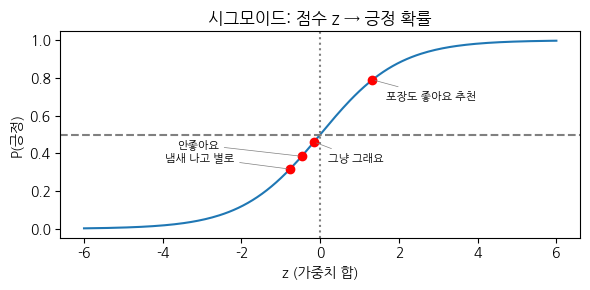

In [54]:
zz = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3))
plt.plot(zz, 1 / (1 + np.exp(-zz)))
plt.axhline(0.5, color="gray", ls="--"); plt.axvline(0, color="gray", ls=":")
plt.scatter(z, p_manual, color="red", zorder=3)
for k, (zi, pi, t) in enumerate(zip(z, p_manual, test)):
    plt.annotate(t, (zi, pi), textcoords="offset points", xytext=(-90 if k % 2 else 10, 6 if k % 2 else -14),
                 fontsize=8, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
plt.title("시그모이드: 점수 z → 긍정 확률"); plt.xlabel("z (가중치 합)"); plt.ylabel("P(긍정)")
plt.tight_layout(); plt.show()

| 문법 | 뜻 |
|---|---|
| `A @ B` | 행렬 곱 (문장마다 Σ 가중치×값) |
| `model.intercept_[0]` | 절편 b |
| `np.exp(x)` | e의 x제곱 |
| `np.allclose(a, b)` | 두 배열이 (반올림 오차 안에서) 같은가 |

> 확률은 **학습한 패턴과 얼마나 닮았나**이지 '맞을 확률'이 아닙니다.

**워크북에서 쓰는 곳:** 3-4 ai_prob, 3-6 애매 구간

---
## 3.6 비교·평가 (워크북 4)

### 예제 25. 혼동행렬과 정확도·정밀도·재현율 직접 세기
별점 라벨(참고 정답) 10개와 AI 예측 10개를 비교합니다. 쇼핑몰에서는 불만(부정)을 놓치지 않는 것이 중요하므로 **부정**을 기준으로 셉니다.

**▶ 셀 25-1. 혼동행렬** — 실행 후 확인: 대각선(맞음) 3·5, 엇갈림 1·1

In [55]:
y_true = ["긍정"]*4 + ["부정"]*6                                                       # 별점 라벨
y_ai   = ["긍정", "긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "긍정", "부정"]   # AI 예측
pd.crosstab(pd.Series(y_true, name="별점"), pd.Series(y_ai, name="AI"))

AI,긍정,부정
별점,,
긍정,3,1
부정,1,5


**▶ 셀 25-2. TP·FP·FN 세고 지표 계산** — 실행 후 확인: `5 1 1`, 정확도 0.80, 정밀도·재현율 0.83

In [56]:
TP = sum(t == "부정" and p == "부정" for t, p in zip(y_true, y_ai))   # 불만을 불만으로
FP = sum(t == "긍정" and p == "부정" for t, p in zip(y_true, y_ai))   # 칭찬인데 불만이라 함
FN = sum(t == "부정" and p == "긍정" for t, p in zip(y_true, y_ai))   # 불만을 놓침
acc = sum(t == p for t, p in zip(y_true, y_ai)) / len(y_true)
print("TP, FP, FN =", TP, FP, FN)
print(f"정확도 {acc:.2f} | 부정 정밀도 {TP/(TP+FP):.2f} | 부정 재현율 {TP/(TP+FN):.2f}")

TP, FP, FN = 5 1 1
정확도 0.80 | 부정 정밀도 0.83 | 부정 재현율 0.83


| 문법 | 뜻 |
|---|---|
| `A and B` | 두 조건 모두 참 |
| `정확도` | 맞은 수 ÷ 전체 |
| `정밀도(부정) = TP ÷ (TP+FP)` | '불만'이라 한 것 중 진짜 불만 |
| `재현율(부정) = TP ÷ (TP+FN)` | 진짜 불만 중 찾아낸 비율 |

**워크북에서 쓰는 곳:** 4-1 혼동행렬·지표

### 예제 26. 일치율의 함정 — 둘 다 틀려도 일치
규칙과 AI가 같은 답을 낸 비율(일치율)은 높아도, 둘이 **같이 틀린** 경우가 섞여 있습니다.

**▶ 셀 26-1. scikit-learn 평가 보고서** — 실행 후 확인: 부정 행의 precision·recall이 셀 25-2와 같은 0.83

In [57]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_ai, digits=2, zero_division=0))

              precision    recall  f1-score   support

          긍정       0.75      0.75      0.75         4
          부정       0.83      0.83      0.83         6

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10



**▶ 셀 26-2. 일치율과 둘 다 틀린 경우** — 실행 후 확인: 일치율 0.90인데 그중 2건은 둘 다 틀림

In [58]:
y_rule = ["긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "부정", "긍정", "부정"]   # 규칙 예측
agree = sum(a == r for a, r in zip(y_ai, y_rule)) / len(y_ai)
both_wrong = sum(a == r != t for a, r, t in zip(y_ai, y_rule, y_true))
print(f"AI-규칙 일치율 {agree:.2f} — 그중 둘 다 틀린 경우 {both_wrong}건")

AI-규칙 일치율 0.90 — 그중 둘 다 틀린 경우 2건


| 문법 | 뜻 |
|---|---|
| `classification_report(정답, 예측)` | 정밀도·재현율·F1·정확도를 한 번에 |
| `a == r != t` | 연쇄 비교: `a == r` 그리고 `r != t` (같은 답인데 정답과 다름) |

> 일치율은 두 방법이 **얼마나 비슷한가**이지 정확도가 아닙니다.

**워크북에서 쓰는 곳:** 4-2 규칙 vs AI, 4-3 불일치 사례

---
## 정리 — 워크북별로 다시 볼 예제
| 워크북 | 대표 코드 | 예제 |
|---|---|---|
| 0 수집 | `read_csv(sep="\t", header=None)`, `drop_duplicates(keep=False)`, `re.search(PII)`, `groupby().sample()`, `hashlib.md5` | 11, 12, 13, 14, 15 |
| 1 정제·탐색 | `.str`, 새 열, `re.sub`, `re.findall` + `Counter`, `groupby().mean()` | 6, 9, 16, 17 |
| 2 규칙 | `sum(w in text ...)`, `def`, 조건 표현식, `.map(rule)` | 5, 8, 18, 19, 20 |
| 3 AI | `TfidfVectorizer`, `fit_transform`/`transform`, `LogisticRegression`, `predict_proba[:, 1]`, `coef_` | 21, 22, 23, 24 |
| 4 평가 | `crosstab`, 정밀도·재현율, `classification_report`, 일치율 | 9, 25, 26 |

➡️ 실습: `Week06_00_감성데이터수집_실습.ipynb` → `Week06_리뷰감성분석_실습.ipynb`